# STAR Project – ANOVA

**Question:** is the average math score different between small, regular, and regular + aide classes?

**ANOVA** compares the averages of more than two groups. Small p (< 0.05) = the groups really differ.

> 💡 **בעברית:** ANOVA משווה ממוצעים של יותר משתי קבוצות. p קטן (< 0.05) = הקבוצות באמת שונות.

## 1. Setup

Groups = `first_classtype` (like in notebook 01). **Grade 5 is not used** (decision with our advisor).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_spss("../data/raw/STAR_Students.sav")
df = df.copy()

k3 = ["gk", "g1", "g2", "g3"]
grades = ["gk", "g1", "g2", "g3", "g4", "g6", "g7", "g8"]          # no grade 5
grade_labels = ["K", "1", "2", "3", "4", "6", "7", "8"]

df["first_classtype"] = df[[f"{g}classtype" for g in k3]].astype(object).bfill(axis=1).iloc[:, 0]

order = ["SMALL CLASS", "REGULAR CLASS", "REGULAR + AIDE CLASS"]
short = ["Small", "Regular", "Regular + aide"]
colors = ["tab:green", "tab:orange", "tab:blue"]

## 2. ANOVA in kindergarten

Mean of each group with a 95% confidence interval, and the ANOVA result.

,count,mean,std
first_classtype,,,
SMALL CLASS,1762,490.9,49.5
REGULAR CLASS,2032,483.2,47.6
REGULAR + AIDE CLASS,2077,482.8,45.8


ANOVA:  F = 17.20,  p = 3.6e-08


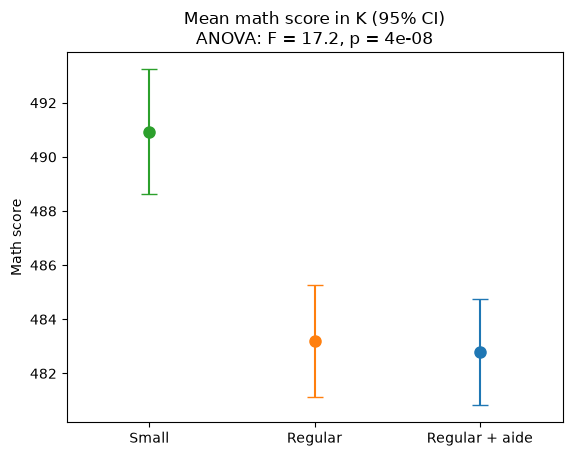

In [2]:
k = df[["first_classtype", "gktmathss"]].dropna()
groups = [k.loc[k["first_classtype"] == c, "gktmathss"] for c in order]

summary = k.groupby("first_classtype")["gktmathss"].agg(["count", "mean", "std"]).reindex(order)
err = 1.96 * summary["std"] / np.sqrt(summary["count"])      # 95% CI half-width
display(summary.round(1))

f_stat, p_value = stats.f_oneway(*groups)
print(f"ANOVA:  F = {f_stat:.2f},  p = {p_value:.2g}")

for i, c in enumerate(colors):
    plt.errorbar(i, summary["mean"].iloc[i], yerr=err.iloc[i], fmt="o", capsize=6, color=c, markersize=8)
plt.xticks(range(3), short)
plt.xlim(-0.5, 2.5)
plt.ylabel("Math score")
plt.title(f"Mean math score in K (95% CI)\nANOVA: F = {f_stat:.1f}, p = {p_value:.1g}")
plt.savefig("../figures/anova_k.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see:**
- Small classes have a higher mean (about 491) than regular and regular + aide (about 483).
- The difference is significant: F = 17.2, p = 4e-08, and the small class CI does not overlap with the other two.
- Regular and regular + aide are almost the same – the aide made no difference.
- Note: the y-axis covers only about 12 points, so the gap looks bigger than it is.

> 💡 **בעברית:** לכיתה הקטנה ממוצע גבוה יותר (כ-491) לעומת שתי האחרות (כ-483).
> ההבדל מובהק (p קטן מאוד), ורווח הסמך שלה לא חופף לאחרים. רגילה ורגילה עם עוזר כמעט זהות.
> שימי לב: ציר Y מכסה רק כ-12 נקודות, אז ההבדל נראה גדול יותר ממה שהוא.

Note: ANOVA is an overall test – it says that *at least one* group is different, not which one.
To compare pairs (small vs regular, etc.) we use the effects graph (notebook 03).

> 💡 ANOVA היא מבחן כללי: היא אומרת ש*לפחות* קבוצה אחת שונה, לא איזו. השוואה של כל זוג נעשה בגרף האפקטים (מחברת 03).

## 3. ANOVA in every grade

The same test in every grade (no grade 5). Each panel has its own y-axis, so compare the groups **inside** a panel.

,students,F,p-value,significant
grade,,,,
K,5871,17.1998,0.0000,yes
1,6598,41.4705,0.0000,yes
2,6065,21.8421,0.0000,yes
3,6077,20.6573,0.0000,yes
4,4331,6.7803,0.0011,yes
6,6422,4.6325,0.0098,yes
7,4888,11.1554,0.0000,yes
8,6213,7.7359,0.0004,yes


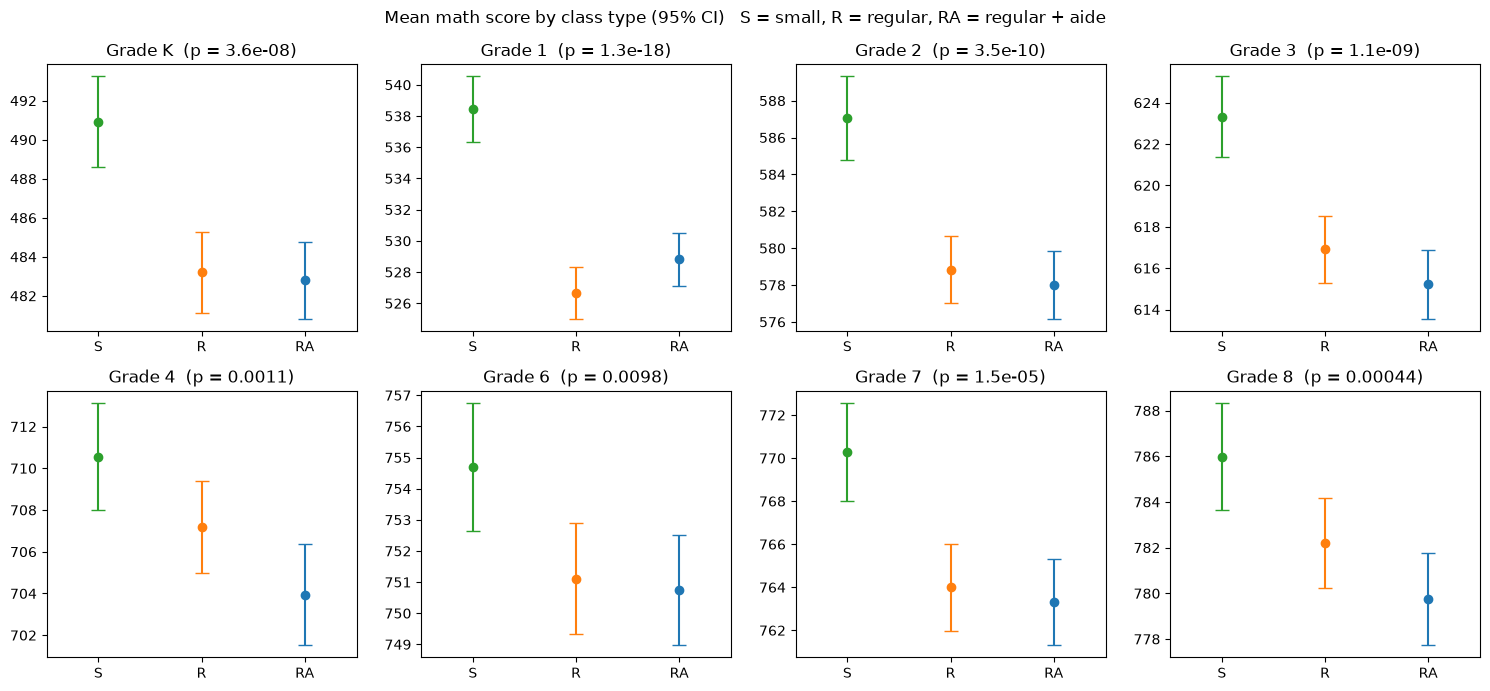

In [3]:
rows = []
for g, lab in zip(grades, grade_labels):
    d = df[["first_classtype", f"{g}tmathss"]].dropna()
    f, p = stats.f_oneway(*[d.loc[d["first_classtype"] == c, f"{g}tmathss"] for c in order])
    rows.append({"grade": lab, "students": len(d), "F": f, "p-value": p})

anova_by_grade = pd.DataFrame(rows).set_index("grade")
anova_by_grade["significant"] = np.where(anova_by_grade["p-value"] < 0.05, "yes", "no")
display(anova_by_grade.round(4))

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, g, lab in zip(axes.flat, grades, grade_labels):
    s = df.groupby("first_classtype")[f"{g}tmathss"].agg(["count", "mean", "std"]).reindex(order)
    e = 1.96 * s["std"] / np.sqrt(s["count"])
    for i, c in enumerate(colors):
        ax.errorbar(i, s["mean"].iloc[i], yerr=e.iloc[i], fmt="o", capsize=5, color=c)
    ax.set_xticks(range(3), ["S", "R", "RA"])
    ax.set_xlim(-0.5, 2.5)
    ax.set_title(f"Grade {lab}  (p = {anova_by_grade.loc[lab, 'p-value']:.2g})")

fig.suptitle("Mean math score by class type (95% CI)   S = small, R = regular, RA = regular + aide")
plt.tight_layout()
plt.savefig("../figures/anova_by_grade.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see:**
- The ANOVA is significant in **every** grade (all p < 0.05).
- **K–3 (experiment years):** small classes (S) are clearly above the other two – their CI does not touch R or RA.
  F is biggest in grade 1 (41.5).
- **Grades 4 and 6 (right after):** S is still on top, but its CI almost touches R. F is smaller (6.8 and 4.6).
- **Grades 7 and 8:** S is again clearly above (F = 11.2 and 7.7). The advantage is still there years later.
- **R vs RA:** close in most grades. In grade 4, R is a bit above RA – so part of the ANOVA result there may come from R vs RA, not only from S.
- **Note:** ANOVA only says that *at least one* group is different. To compare pairs, we use the effects graph (notebook 03).
  Also, p-values here are probably too small (students in the same class/school are similar, and we ran 8 tests).

> 💡 **בעברית:**
> - ההבדל מובהק בכל השכבות.
> - **גן–ג':** הכיתה הקטנה ברור מעל, והרווח שלה לא נוגע באחרות. F הכי גדול בכיתה א' (41.5).
> - **ד' ו-ו':** הקטנה עדיין למעלה, אבל הרווח שלה כמעט נוגע ברגילה. F קטן יותר (6.8 ו-4.6).
> - **ז' ו-ח':** הקטנה שוב ברור מעל (F = 11.2 ו-7.7). היתרון קיים גם שנים אחרי.
> - **רגילה מול עם עוזר:** קרובות ברוב השנים. בכיתה ד' הרגילה קצת מעל, אז חלק מההבדל שם אולי בא מהן ולא רק מהקטנה.
> - **שימי לב:** ANOVA אומרת רק ש*לפחות* קבוצה אחת שונה. השוואה של כל זוג נעשה בגרף האפקטים (מחברת 03).
>   וה-p כאן כנראה קטנים מדי (תלמידים באותה כיתה דומים, והרצנו 8 מבחנים).

**Limitations:** this simple ANOVA ignores schools (randomization was inside schools) and dropout. It is a first look only.

> 💡 **בעברית:** ה-ANOVA הזו לא מתחשבת בבתי ספר ובנשירה. זה מבט ראשון בלבד.